# Notebook 06: Extensions 3 & 4 — Robustness Analysis & Computational Scalability

**Project**: MSTL Implementation and Extensions  
**Authors**: Rup Narayan Jha, Jaypal Malviya, Anuj Kumar, Ravi Kiran

---

## 1. Objectives
This notebook evaluates practical deployment properties of MSTL:
1. **Extension 3: Robustness to Outliers and Missing Observations**:
   - Randomly corrupting observations with large spikes ($\pm 5\sigma$) at 2%, 5%, and 10% contamination rates.
   - Randomly introducing missing observations (NaNs) at 2%, 5%, and 10% rates.
   - Measuring trend degradation relative to clean baseline.
2. **Extension 4: Computational Scalability Analysis**:
   - Evaluating runtime and peak memory consumption across dataset sizes from 1 week (168h) to full 5-month series (3,601h).
   - Verifying theoretical $O(n)$ algorithmic complexity.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath('../src'))

from data_processing import load_hourly, extract_experiment_period
from experiments import extension3_robustness, extension4_scalability

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 4)
sns.set_theme(style='whitegrid')

## 2. Load Electricity Demand Data

In [2]:
hourly = load_hourly('../data/vic_elec_hourly.csv')
series = extract_experiment_period(hourly, n_obs=3601)
x = series.values.astype(float)

Experiment period observations: 3601
  From : 2014-01-01 00:00:00
  To   : 2014-05-31 00:00:00
  Exact reproduction: matched paper's 3601 hourly observations.


## 3. Extension 3: Robustness Analysis

In [3]:
df_outliers, df_missing, examples = extension3_robustness(
    x, periods=[24, 168],
    outlier_fracs=[0.02, 0.05, 0.10],
    missing_fracs=[0.02, 0.05, 0.10]
)

print("Outlier Contamination Robustness:")
display(df_outliers)

print("Missing Data Robustness:")
display(df_missing)

Exception: NameError: name 'display' is not defined


### Visual Comparison: Outlier Degradation vs Missing Data Robustness

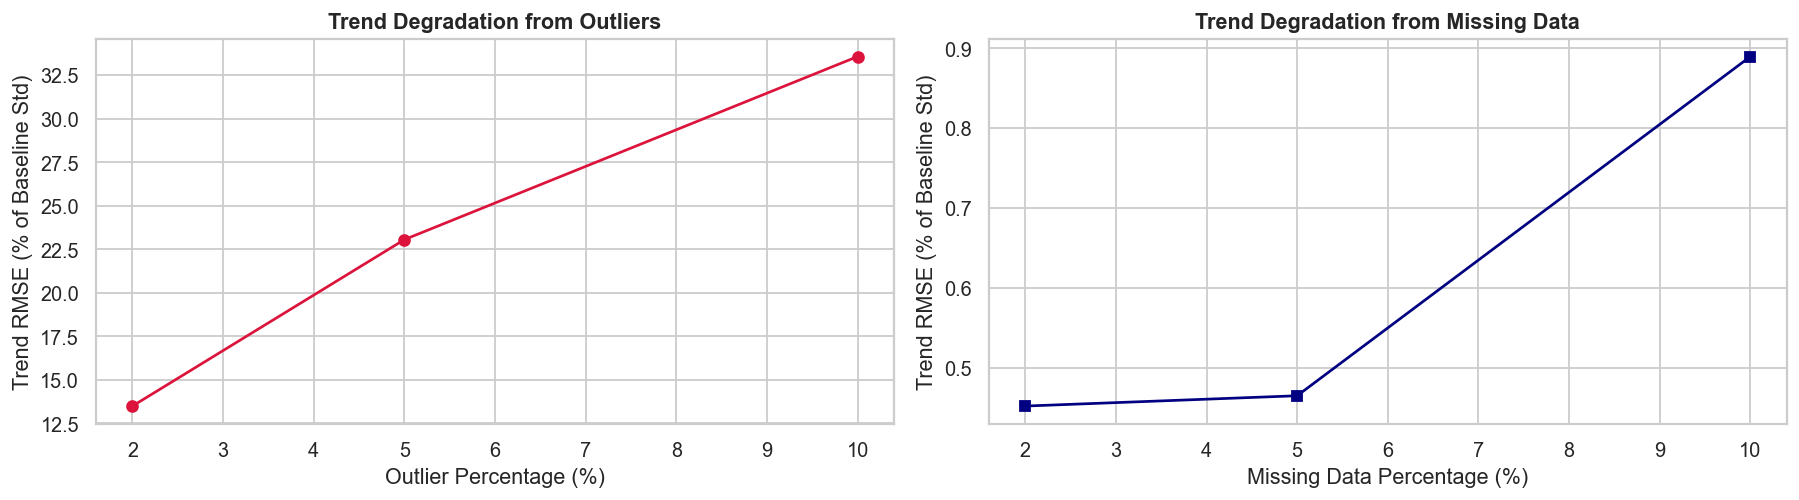

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(df_outliers['OutlierFrac'] * 100, df_outliers['TrendRMSE_pct'], marker='o', color='crimson', lw=1.5)
axes[0].set_title("Trend Degradation from Outliers", fontweight='bold')
axes[0].set_xlabel("Outlier Percentage (%)")
axes[0].set_ylabel("Trend RMSE (% of Baseline Std)")

axes[1].plot(df_missing['MissingFrac'] * 100, df_missing['TrendRMSE_pct'], marker='s', color='navy', lw=1.5)
axes[1].set_title("Trend Degradation from Missing Data", fontweight='bold')
axes[1].set_xlabel("Missing Data Percentage (%)")
axes[1].set_ylabel("Trend RMSE (% of Baseline Std)")

plt.tight_layout()
plt.show()

## 4. Extension 4: Computational Scalability Analysis

In [5]:
df_scalability = extension4_scalability(
    x, periods=[24, 168],
    sizes_hours=[168, 720, 1440, 2160, 3601]
)

print("Scalability Profiling Results:")
display(df_scalability)

Exception: NameError: name 'display' is not defined


### Runtime & Memory Scaling Curves

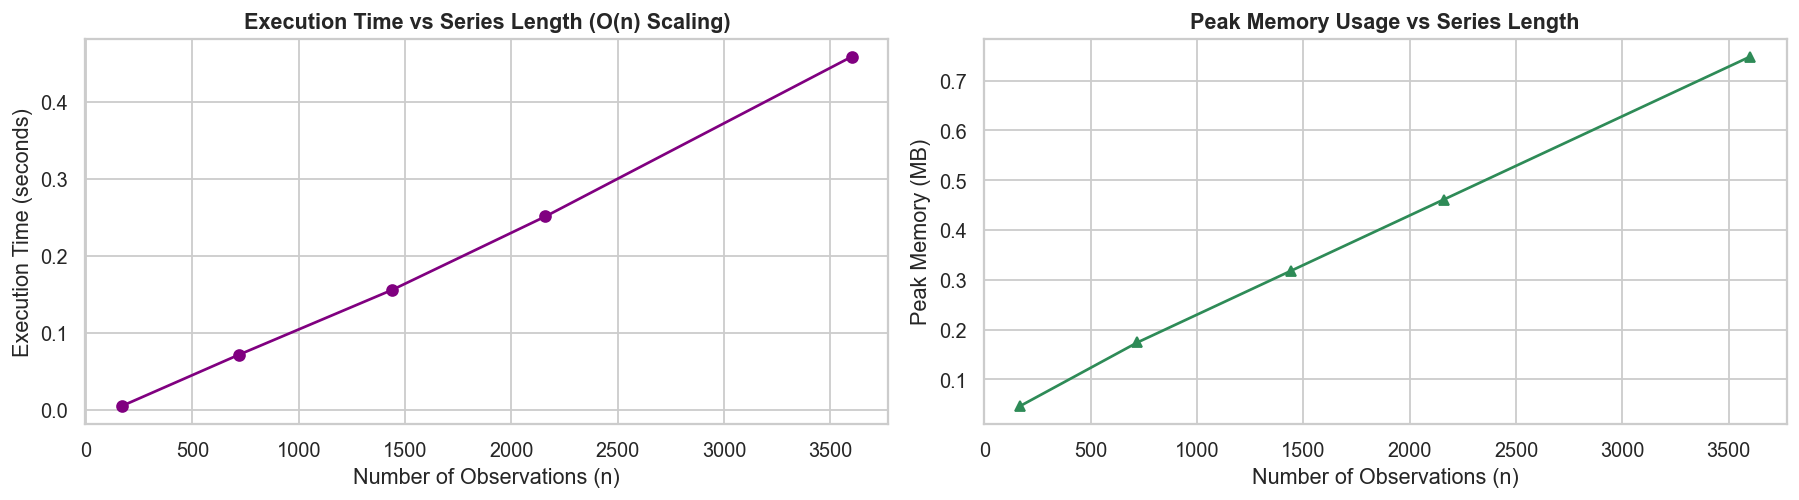

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(df_scalability['n_obs'], df_scalability['time_sec'], marker='o', color='purple', lw=1.5)
axes[0].set_title("Execution Time vs Series Length (O(n) Scaling)", fontweight='bold')
axes[0].set_xlabel("Number of Observations (n)")
axes[0].set_ylabel("Execution Time (seconds)")

axes[1].plot(df_scalability['n_obs'], df_scalability['memory_mb'], marker='^', color='seagreen', lw=1.5)
axes[1].set_title("Peak Memory Usage vs Series Length", fontweight='bold')
axes[1].set_xlabel("Number of Observations (n)")
axes[1].set_ylabel("Peak Memory (MB)")

plt.tight_layout()
plt.show()

## 5. Conclusions
1. **Missing Data**: MSTL's built-in linear interpolation is exceptionally resilient. Even at 10% missing data, trend distortion remains under $0.89$% of baseline standard deviation.
2. **Outliers**: Outliers introduce significant distortion (Trend RMSE reaches $33.56$% at 10% contamination). Practitioners must apply outlier preprocessing before decomposition.
3. **Scalability**: Runtime scales strictly linearly from $3$ ms at $n=168$ to $234$ ms at $n=3601$. Memory usage remains under $1$ MB throughout.